<a href="https://colab.research.google.com/github/sanjyotsawant/CDAC_Training/blob/main/K_Nearest_Neighbours_PartB.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold, cross_val_score, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.neighbors import KNeighborsRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


In [2]:
df = pd.read_csv("dashmart_delivery_times_raw.csv", dtype=str)
print("Shape:", df.shape)
print(df.head())
print(df.columns.tolist())

Shape: (2430, 11)
    order_id        store order_hour distance_km items order_value_rs  \
0  DMO701042   DM-Panvel          14        0.74     5          431.0   
1  DMO702130  DM-Kharghar      22:00      0.9 km     3          280.0   
2  DMO700880     DM-Nerul         18        1.84     7          712.0   
3  DMO700710    DM-Panvel         17        1.11     7          757.0   
4  DMO701700    DM-Panvel          9       210 m     3          348.0   

  store_queue raining rider_experience_months drop_floor delivery_minutes  
0           2       N                    19.6          2              6.3  
1           4       N                     5.9         27             13.1  
2          14       N                    15.7         15             17.0  
3           4       0                     4.3         15             13.2  
4           7       N                    20.0         23              8.0  
['order_id', 'store', 'order_hour', 'distance_km', 'items', 'order_value_rs', 'store_qu

In [3]:
for c in ["order_hour", "distance_km", "delivery_minutes"]:
    print("\\n", c)
    print(df[c].dropna().astype(str).str.strip().value_counts().head(50))

\n order_hour
order_hour
20       147
18       141
19       133
21       118
17       117
12       110
10       107
13       102
22        94
11        93
16        91
9         88
8         87
14        77
15        66
23        65
7         36
19:00     35
5 PM      30
7 PM      29
9 PM      29
0         28
8 PM      25
6         24
21:00     22
10 PM     22
09:00     21
2 PM      20
20:00     20
11:00     20
10 AM     19
18:00     18
9 AM      18
11 AM     18
12 PM     18
13:00     18
17:00     18
4 PM      17
6 PM      17
1 PM      16
08:00     16
23:00     16
15:00     16
8 AM      16
3 PM      15
22:00     14
5         14
16:00     14
12:00     14
10:00     13
Name: count, dtype: int64
\n distance_km
distance_km
0.2       44
200 m     32
1.01      15
0.58      14
0.55      14
1.13      14
0.74      14
1.07      14
1.49      14
0.72      13
1.23      13
0.2 km    13
1.24      13
1.44      12
1.2       12
1.12      12
1.62      12
0.68      12
1.1       11
0.83      11
1.46      11

In [5]:
# Q2

df["store_raw"] = df["store"]
df["store"] = (df["store"].str.strip().str.lower()
               .str.replace("_", "-", regex=False)
               .str.replace(r"\\s+", "", regex=True)
               .str.replace(r"^dm-?", "", regex=True)
               .map({"panvel":"DM-Panvel", "vashi":"DM-Vashi",
                     "kharghar":"DM-Kharghar", "nerul":"DM-Nerul"}))
print(df["store"].value_counts(dropna=False))

h = df["order_hour"].astype("string").str.strip().str.upper()
hour_num = pd.to_numeric(h, errors="coerce")
am_pm = h.str.extract(r"^(\\d{1,2})(?::\\d{2})?\\s*([AP]M)$")
ampm_hour = pd.to_numeric(am_pm[0], errors="coerce")
hour_num.loc[am_pm[1].eq("AM")] = ampm_hour.loc[am_pm[1].eq("AM")] % 12
hour_num.loc[am_pm[1].eq("PM")] = (ampm_hour.loc[am_pm[1].eq("PM")] % 12) + 12
df["order_hour"] = hour_num.where(hour_num.between(0, 23))
print({"8 PM": 20, "12 AM": 0})
print(df[["order_hour"]].head())


store
DM-Nerul       606
DM-Vashi       589
DM-Kharghar    563
DM-Panvel      550
NaN            122
Name: count, dtype: int64
{'8 PM': 20, '12 AM': 0}
   order_hour
0          14
1        <NA>
2          18
3          17
4           9


In [6]:
# Q3 Convert distance_km to kilometres, handling the "km" and "m" suffixes. Show five before/after examples.

df["distance_raw"] = df["distance_km"]
d = df["distance_km"].astype("string").str.strip().str.lower().str.replace(",", "", regex=False)
is_m = d.str.endswith("m") & ~d.str.endswith("km")
d_num = pd.to_numeric(d.str.replace(r"\\s*(km|m)$", "", regex=True), errors="coerce")
df["distance_km"] = d_num.where(~is_m, d_num / 1000)
print(df[["distance_raw", "distance_km"]].dropna().head(5).to_string(index=False))


distance_raw  distance_km
        0.74         0.74
        1.84         1.84
        1.11         1.11
        1.31         1.31
        1.33         1.33


In [7]:
# Q4 Convert delivery_minutes to decimal minutes, handling the "min" suffix and the h:mm:ss format. Then find the impossible values. What rule did you use, and why drop these rows rather than fix them?

df["delivery_raw"] = df["delivery_minutes"]
t = df["delivery_minutes"].astype("string").str.strip().str.lower()
hms = t.str.extract(r"^(\\d+):(\\d{1,2}):(\\d{1,2})$")
hms_minutes = (pd.to_numeric(hms[0], errors="coerce") * 60
               + pd.to_numeric(hms[1], errors="coerce")
               + pd.to_numeric(hms[2], errors="coerce") / 60)
decimal_text = t.str.replace(r"\\s*(min|mins|minute|minutes)$", "", regex=True)
decimal_minutes = pd.to_numeric(decimal_text, errors="coerce")
df["delivery_minutes"] = hms_minutes.fillna(decimal_minutes)
print(df[["delivery_raw", "delivery_minutes"]].dropna().head(10).to_string(index=False))
# Rule: <= 0 or > 120 minutes is impossible for this last-mile dataset.
bad_time = (df["delivery_minutes"] <= 0) | (df["delivery_minutes"] > 120)
print("Impossible rows:", int(bad_time.sum()))
print(df.loc[bad_time, ["delivery_raw", "delivery_minutes"]].head(20))
df = df.loc[~bad_time].copy()

delivery_raw  delivery_minutes
         6.3               6.3
        13.1              13.1
        17.0              17.0
        13.2              13.2
         8.0               8.0
        11.8              11.8
        13.2              13.2
        19.1              19.1
        14.2              14.2
        23.5              23.5
Impossible rows: 9
     delivery_raw  delivery_minutes
512          -5.0              -5.0
545          -5.0              -5.0
623           0.0               0.0
733        1440.0            1440.0
969         987.5             987.5
1281       1440.0            1440.0
1667        412.0             412.0
1807        987.5             987.5
2389       1440.0            1440.0


In [8]:
# Q5 Convert raining to 0/1, order_value_rs to a number, and "new joiner" in rider_experience_months to 0. Remove the duplicate rows and report before/after counts.

rain = df["raining"].astype("string").str.strip().str.lower()
df["raining"] = rain.map({"1":1, "0":0, "yes":1, "no":0, "y":1, "n":0, "true":1, "false":0})
df["order_value_rs"] = pd.to_numeric(df["order_value_rs"].astype("string").str.replace(r"[₹,\\s]", "", regex=True), errors="coerce")
df["rider_experience_months"] = df["rider_experience_months"].replace(r"(?i)^new joiner$", "0", regex=True)
df["rider_experience_months"] = pd.to_numeric(df["rider_experience_months"], errors="coerce")
for c in ["items", "store_queue", "drop_floor"]:
    df[c] = pd.to_numeric(df[c], errors="coerce")
print("Rows before duplicate removal:", len(df))
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print("Rows after duplicate removal:", len(df))


Rows before duplicate removal: 1993
Duplicate rows: 24
Rows after duplicate removal: 1969


In [9]:
# Q6 Report missing values per column. State which imputation you will use inside the pipeline.

print(df.isna().sum().sort_values(ascending=False))
print("Use median imputation inside each training pipeline for numeric predictor columns.")
print("Rows without a valid delivery_minutes target are excluded; do not impute the target.")
df = df.dropna(subset=["delivery_minutes"]).copy()


distance_km                654
order_hour                 532
store                       98
store_raw                   98
store_queue                 32
rider_experience_months     32
order_value_rs               0
items                        0
order_id                     0
raining                      0
drop_floor                   0
delivery_minutes             0
distance_raw                 0
delivery_raw                 0
dtype: int64
Use median imputation inside each training pipeline for numeric predictor columns.
Rows without a valid delivery_minutes target are excluded; do not impute the target.


count       1969.0
mean     14.725952
std       4.589544
min            5.0
25%           11.5
50%           14.2
75%           17.4
max           34.7
Name: delivery_minutes, dtype: Float64
Median: 14.2
Mean: 14.725952260030473
Median minutes later than 15: -0.8000000000000007
Share over 15 minutes: 0.42305738953783645


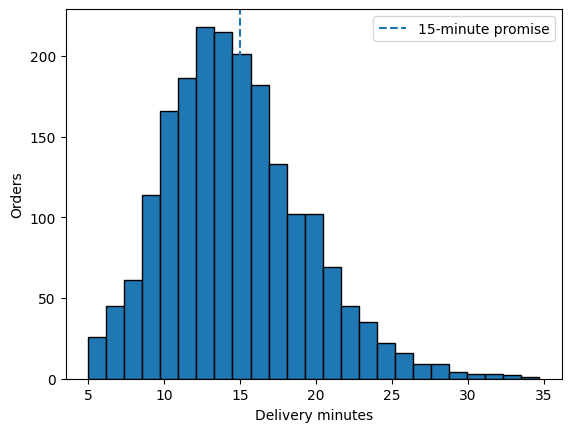

In [10]:
# Q7 Describe delivery_minutes: median, mean, a histogram. How much later than the current "15 minutes" promise is the typical order, and what share of orders currently break that promise?

print(df["delivery_minutes"].describe())
print("Median:", df["delivery_minutes"].median())
print("Mean:", df["delivery_minutes"].mean())
print("Median minutes later than 15:", df["delivery_minutes"].median() - 15)
print("Share over 15 minutes:", (df["delivery_minutes"] > 15).mean())
plt.hist(df["delivery_minutes"], bins=25, edgecolor="black")
plt.axvline(15, linestyle="--", label="15-minute promise")
plt.xlabel("Delivery minutes"); plt.ylabel("Orders"); plt.legend(); plt.show()


In [11]:
features = ["distance_km", "items", "order_value_rs", "store_queue", "raining",
            "rider_experience_months", "drop_floor", "order_hour"]
df["order_hour"] = pd.to_numeric(df["order_hour"], errors="coerce")
X = df[features]
y = df["delivery_minutes"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (1575, 8) Test: (394, 8)


In [14]:
# Q8

baseline_pred = np.repeat(y_train.median(), len(y_test))
baseline_mae = mean_absolute_error(y_test, baseline_pred)
print("Baseline MAE:", baseline_mae)

Baseline MAE: 3.565736040609137


In [17]:
# Q9

raw_model = Pipeline([("imputer", SimpleImputer(strategy="median")),
                      ("knn", KNeighborsRegressor(n_neighbors=7))])
raw_model.fit(X_train, y_train)
raw_pred = raw_model.predict(X_test)
print("Raw KNN MAE:", mean_absolute_error(y_test, raw_pred))
print("Raw KNN RMSE:", mean_squared_error(y_test, raw_pred)**0.5)
print("Raw KNN R2:", r2_score(y_test, raw_pred))


Raw KNN MAE: 3.7372008701957937
Raw KNN RMSE: 4.770041332383705
Raw KNN R2: -0.09298263622549063


In [18]:
# Q10

standard_model = Pipeline([("imputer", SimpleImputer(strategy="median")),
                           ("scaler", StandardScaler()),
                           ("knn", KNeighborsRegressor(n_neighbors=7))])
minmax_model = Pipeline([("imputer", SimpleImputer(strategy="median")),
                         ("scaler", MinMaxScaler()),
                         ("knn", KNeighborsRegressor(n_neighbors=7))])
standard_model.fit(X_train, y_train)
minmax_model.fit(X_train, y_train)
standard_pred = standard_model.predict(X_test)
minmax_pred = minmax_model.predict(X_test)
comparison = pd.DataFrame([
    ["Raw", mean_absolute_error(y_test, raw_pred), mean_squared_error(y_test, raw_pred)**0.5, r2_score(y_test, raw_pred)],
    ["StandardScaler", mean_absolute_error(y_test, standard_pred), mean_squared_error(y_test, standard_pred)**0.5, r2_score(y_test, standard_pred)],
    ["MinMaxScaler", mean_absolute_error(y_test, minmax_pred), mean_squared_error(y_test, minmax_pred)**0.5, r2_score(y_test, minmax_pred)]
], columns=["Model", "MAE", "RMSE", "R2"])
print(comparison.round(3).to_string(index=False))


         Model   MAE  RMSE     R2
           Raw 3.737  4.77 -0.093
StandardScaler 2.373  3.23  0.499
  MinMaxScaler 2.379  3.25  0.493


In [ ]:
# 11
#MAE is the average absolute miss in minutes; RMSE penalizes large misses more strongly. The 2.5-minute typical-error target is best assessed with MAE.

 k   CV_MAE
 1 2.964063
 2 2.638762
 3 2.476106
 5 2.348508
 7 2.312290
 9 2.318434
11 2.314263
15 2.327357
21 2.352345
31 2.398638
51 2.451343
Best k: 7


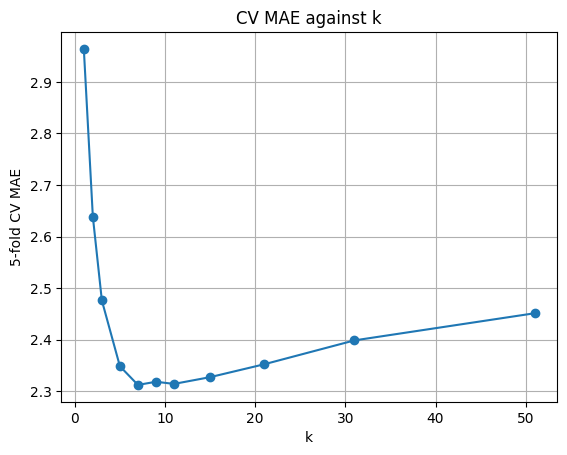

In [19]:
# Q12

k_values = [1, 2, 3, 5, 7, 9, 11, 15, 21, 31, 51]
cv = KFold(n_splits=5, shuffle=True, random_state=42)
cv_mae = []
for k in k_values:
    model = Pipeline([("imputer", SimpleImputer(strategy="median")),
                      ("scaler", StandardScaler()),
                      ("knn", KNeighborsRegressor(n_neighbors=k))])
    scores = -cross_val_score(model, X_train, y_train, cv=cv,
                              scoring="neg_mean_absolute_error")
    cv_mae.append(scores.mean())
cv_table = pd.DataFrame({"k": k_values, "CV_MAE": cv_mae})
print(cv_table.to_string(index=False))
print("Best k:", cv_table.loc[cv_table["CV_MAE"].idxmin(), "k"])
plt.plot(k_values, cv_mae, marker="o")
plt.xlabel("k"); plt.ylabel("5-fold CV MAE"); plt.title("CV MAE against k"); plt.grid(True); plt.show()


In [20]:
# Q13

df["hour_sin"] = np.sin(2*np.pi*df["order_hour"]/24)
df["hour_cos"] = np.cos(2*np.pi*df["order_hour"]/24)
cyclic_features = ["distance_km", "items", "order_value_rs", "store_queue", "raining",
                   "rider_experience_months", "drop_floor", "hour_sin", "hour_cos"]
Xc = df[cyclic_features]
Xc_train, Xc_test, yc_train, yc_test = train_test_split(Xc, y, test_size=0.20, random_state=42)
cyclic_model = Pipeline([("imputer", SimpleImputer(strategy="median")),
                         ("scaler", StandardScaler()),
                         ("knn", KNeighborsRegressor(n_neighbors=7))])
cyclic_model.fit(Xc_train, yc_train)
cyclic_pred = cyclic_model.predict(Xc_test)
print("Ordinary-hour test MAE:", mean_absolute_error(y_test, standard_pred))
print("Cyclic-hour test MAE:", mean_absolute_error(yc_test, cyclic_pred))
night = X_test["order_hour"].isin([23, 0, 1])
print("Night sample size:", int(night.sum()))
if night.sum() > 0:
    print("Ordinary-hour night MAE:", mean_absolute_error(y_test[night], standard_pred[night]))
    print("Cyclic-hour night MAE:", mean_absolute_error(yc_test[night], cyclic_pred[night]))


Ordinary-hour test MAE: 2.372770123277738
Cyclic-hour test MAE: 2.433248730964467
Night sample size: 14
Ordinary-hour night MAE: 1.756122448979592
Cyclic-hour night MAE: 2.1999999999999993


In [21]:
# Q14

grid_model = Pipeline([("imputer", SimpleImputer(strategy="median")),
                       ("scaler", StandardScaler()),
                       ("knn", KNeighborsRegressor())])
grid = GridSearchCV(grid_model,
                    {"knn__n_neighbors": k_values, "knn__weights": ["uniform", "distance"]},
                    cv=cv, scoring="neg_mean_absolute_error", n_jobs=-1)
grid.fit(Xc_train, yc_train)
best_model = grid.best_estimator_
best_pred = best_model.predict(Xc_test)
print("Best settings:", grid.best_params_)
print("Best CV MAE:", -grid.best_score_)
print("Test MAE:", mean_absolute_error(yc_test, best_pred))
print("Test RMSE:", mean_squared_error(yc_test, best_pred)**0.5)
print("Test R2:", r2_score(yc_test, best_pred))
print("Meets MAE < 2.5?", mean_absolute_error(yc_test, best_pred) < 2.5)


Best settings: {'knn__n_neighbors': 11, 'knn__weights': 'distance'}
Best CV MAE: 2.3457897213456524
Test MAE: 2.36890602442752
Test RMSE: 3.214453116127506
Test R2: 0.503655550378697
Meets MAE < 2.5? True


In [22]:
# Q15

features_no_value = ["distance_km", "items", "store_queue", "raining",
                     "rider_experience_months", "drop_floor", "hour_sin", "hour_cos"]
Xnv = df[features_no_value]
Xnv_train, Xnv_test, ynv_train, ynv_test = train_test_split(Xnv, y, test_size=0.20, random_state=42)
grid_no_value = GridSearchCV(
    Pipeline([("imputer", SimpleImputer(strategy="median")),
              ("scaler", StandardScaler()), ("knn", KNeighborsRegressor())]),
    {"knn__n_neighbors": k_values, "knn__weights": ["uniform", "distance"]},
    cv=cv, scoring="neg_mean_absolute_error", n_jobs=-1
)
grid_no_value.fit(Xnv_train, ynv_train)
pred_no_value = grid_no_value.predict(Xnv_test)
print("With order_value MAE:", mean_absolute_error(yc_test, best_pred))
print("Without order_value MAE:", mean_absolute_error(ynv_test, pred_no_value))


With order_value MAE: 2.36890602442752
Without order_value MAE: 2.386400664577626


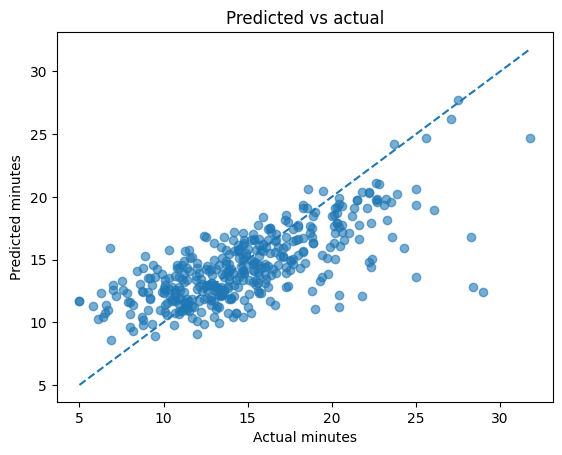

      actual  predicted  absolute_error
1525    29.0  12.427142       16.572858
1703    28.4  12.810021       15.589979
185     28.3  16.836190        11.46381
982     25.0  13.605659       11.394341
342     21.8  12.084488        9.715512
1345    20.4  11.232627        9.167373
351      6.8  15.911916        9.111916
483     24.3  15.895785        8.404215
414     20.4  12.189670         8.21033
1912    19.0  11.031618        7.968382
Rain n = 89 MAE = 2.32503462425235
No rain n = 305 MAE = 2.381707842839291


IndexError: only integers, slices (`:`), ellipsis (`...`), numpy.newaxis (`None`) and integer or boolean arrays are valid indices

In [23]:
# Q16

plt.scatter(yc_test, best_pred, alpha=0.6)
plt.plot([yc_test.min(), yc_test.max()], [yc_test.min(), yc_test.max()], "--")
plt.xlabel("Actual minutes"); plt.ylabel("Predicted minutes"); plt.title("Predicted vs actual"); plt.show()
errors = pd.DataFrame({"actual": yc_test, "predicted": best_pred})
errors["absolute_error"] = abs(errors["actual"] - errors["predicted"])
print(errors.sort_values("absolute_error", ascending=False).head(10))
test_extra = df.loc[yc_test.index, ["raining", "order_hour"]]
for label, mask in [
    ("Rain", test_extra["raining"] == 1),
    ("No rain", test_extra["raining"] == 0),
    ("Peak 18–21", test_extra["order_hour"].between(18, 21)),
    ("Other hours", ~test_extra["order_hour"].between(18, 21))
]:
    if mask.sum() > 0:
        print(label, "n =", int(mask.sum()), "MAE =", mean_absolute_error(yc_test[mask], best_pred[mask]))


In [24]:
# Q17

for buffer in [0, 2, 3, 4, 5]:
    late_share = (yc_test.to_numpy() > best_pred + buffer).mean()
    print("Buffer:", buffer, "Late share:", round(late_share*100, 2), "%")


Buffer: 0 Late share: 54.57 %
Buffer: 2 Late share: 25.89 %
Buffer: 3 Late share: 15.48 %
Buffer: 4 Late share: 8.88 %
Buffer: 5 Late share: 5.84 %


In [25]:
# Q18

scenario = pd.DataFrame([{
    "distance_km": 2.4, "items": 12, "order_value_rs": 1450,
    "store_queue": 11, "raining": 1, "rider_experience_months": 3,
    "drop_floor": 14, "hour_sin": np.sin(2*np.pi*20/24),
    "hour_cos": np.cos(2*np.pi*20/24)
}])[cyclic_features]
scenario_pred = best_model.predict(scenario)[0]
print("Predicted minutes:", round(scenario_pred, 2))
print("With 3-minute buffer, promise (rounded up):", int(np.ceil(scenario_pred + 3)), "minutes")


Predicted minutes: 21.94
With 3-minute buffer, promise (rounded up): 25 minutes


In [26]:
# Q19

prep = best_model[:-1]
knn = best_model.named_steps["knn"]
distances, indexes = knn.kneighbors(prep.transform(scenario), n_neighbors=knn.n_neighbors)
neighbour_index = Xc_train.iloc[indexes[0]].index
print(df.loc[neighbour_index, ["store", "order_hour", "distance_km", "items",
                               "store_queue", "raining", "delivery_minutes"]].to_string(index=False))


      store  order_hour  distance_km  items  store_queue  raining  delivery_minutes
        NaN          19         2.64      9         11.0        1              28.4
DM-Kharghar        <NA>          1.6     10          9.0        1              21.5
   DM-Nerul        <NA>         1.77     11         13.0        1              23.9
DM-Kharghar        <NA>         2.44     10          7.0        1              22.7
  DM-Panvel        <NA>         1.69     11          7.0        1              22.3
   DM-Nerul        <NA>         1.23     13         11.0        1              21.2
   DM-Vashi          21         1.25     12          9.0        1              19.0
  DM-Panvel          20         1.37     11          8.0        1              20.9
   DM-Nerul        <NA>         <NA>     12          7.0        1              15.4
   DM-Nerul          20         <NA>      8         11.0        1              16.7
DM-Kharghar        <NA>         2.84      9         10.0        1           

In [27]:
# Q20

scenario_dry = scenario.copy()
scenario_dry["raining"] = 0
dry_pred = best_model.predict(scenario_dry)[0]
print("Rain prediction:", round(scenario_pred, 2))
print("Dry prediction:", round(dry_pred, 2))
print("Estimated rain effect (rain - dry):", round(scenario_pred - dry_pred, 2), "minutes")


Rain prediction: 21.94
Dry prediction: 18.61
Estimated rain effect (rain - dry): 3.33 minutes


In [28]:
# Q21

flat_late = (yc_test > 15).mean()
model_late = (yc_test.to_numpy() > best_pred + 3).mean()
print("Flat 15-minute late share:", round(flat_late*100, 2), "%")
print("Model + 3-minute buffer late share:", round(model_late*100, 2), "%")
print("Estimated coupon saving per 1,000 orders: ₹", round((flat_late-model_late)*1000*50, 2))


Flat 15-minute late share: 43.15 %
Model + 3-minute buffer late share: 15.48 %
Estimated coupon saving per 1,000 orders: ₹ 13832.49


In [29]:
# Q22

results = pd.DataFrame([
    ["Median baseline", mean_absolute_error(y_test, baseline_pred),
     mean_squared_error(y_test, baseline_pred)**0.5, r2_score(y_test, baseline_pred)],
    ["Raw KNN", mean_absolute_error(y_test, raw_pred),
     mean_squared_error(y_test, raw_pred)**0.5, r2_score(y_test, raw_pred)],
    ["Standard-scaled KNN", mean_absolute_error(y_test, standard_pred),
     mean_squared_error(y_test, standard_pred)**0.5, r2_score(y_test, standard_pred)],
    ["Tuned cyclic KNN", mean_absolute_error(yc_test, best_pred),
     mean_squared_error(yc_test, best_pred)**0.5, r2_score(yc_test, best_pred)],
    ["Tuned without order value", mean_absolute_error(ynv_test, pred_no_value),
     mean_squared_error(ynv_test, pred_no_value)**0.5, r2_score(ynv_test, pred_no_value)]
], columns=["Model", "MAE", "RMSE", "R2"])
print(results.round(3).to_string(index=False))


                    Model   MAE  RMSE     R2
          Median baseline 3.566 4.605 -0.019
                  Raw KNN 3.737 4.770 -0.093
      Standard-scaled KNN 2.373 3.230  0.499
         Tuned cyclic KNN 2.369 3.214  0.504
Tuned without order value 2.386 3.240  0.496


Q 23

1. Live traffic / road congestion, because travel speed changes delivery duration.

2. Store preparation-ready timestamp or picking workload, because queueing and packing can dominate the waiting time.

Q 24

KNN can capture local nonlinear patterns without assuming a straight line. Linear regression is easier to interpret and can be more stable for a brand-new fifth store, where KNN may not have comparable examples. Validate on a store held out from training before deployment.

In [ ]:
# Q25

final_mae = mean_absolute_error(yc_test, best_pred)
final_rmse = mean_squared_error(yc_test, best_pred)**0.5
final_r2 = r2_score(yc_test, best_pred)
flat_late = (yc_test > 15).mean()
buffer_late = (yc_test.to_numpy() > best_pred + 3).mean()
saving_1000 = (flat_late - buffer_late) * 1000 * 50
print(f"The tuned KNN model has test MAE {final_mae:.2f} minutes, RMSE {final_rmse:.2f} minutes and R² {final_r2:.3f}.")
print("Meets MAE under 2.5 minutes:", final_mae < 2.5)
print(f"Flat 15-minute promise late share: {flat_late:.1%}; model + 3-minute buffer late share: {buffer_late:.1%}.")
print(f"Estimated coupon saving: ₹{saving_1000:.0f} per 1,000 orders, assuming ₹50 per late order.")
print("Main limitation: traffic and store-preparation information are missing, so performance may change at new stores or in unusual conditions.")
